# 02b · EDA: BEV vs. ICE Across Rating Features
**BEV vs. ICE Motor Property Insurance**

Notebooks 01 and 02 looked at policies and claims separately. Here we join them and look at claims through the features we price on: district, vehicle value, driver age and vehicle age.

**Questions**
1. Do BEVs cost more to repair in every district?
2. Do BEVs claim more often in every district?
3. How do claim cost and write-offs change with vehicle value?
4. How does claim frequency change with driver age?
5. How do repair cost and write-offs change as cars get older?

**Data:** BEV and ICE policies (Hybrid excluded), with own-damage claims (`Own_Damage_Amount > 0`) inside the policy period. The 2025-01-19 storm is excluded, as in notebooks 03–04. Severity excludes the few amounts above 2 × vehicle value, and the write-off rate excludes theft.

**Why the storm is excluded:** the 2025-01-19 storm is a catastrophe event: a rare, one-off tail loss that cannot be rated from a policy's own characteristics. Insurers cover such events through reinsurance and a separate catastrophe loading, not through the baseline pure-premium tariff, so it is left out of the attritional analysis. The claims stay in the data, flagged as `is_cat_event`.

## 1. Setup and Data

In [1]:
# suppressWarnings hides "package built under R 4.5.x" notices
suppressWarnings(suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
  library(patchwork)
}))

options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 110,
        dplyr.summarise.inform = FALSE)
theme_set(theme_minimal(base_size = 12))

pt_colours <- c(BEV = "#1b9e77", Hybrid = "#7570b3", ICE = "#d95f02")

# Path to a file in data/processed/; works from notebooks/ or the repository root
processed_path <- function(file) {
  path <- file.path(c("../data/processed", "data/processed"), file) |> keep(file.exists) |> first()
  if (is.na(path)) stop("Cannot find ", file, " (run src/01_clean_datasets.R first)")
  path
}

policies <- read_rds(processed_path("policies_cleaned.rds")) |>
  filter(Powertrain %in% c("BEV", "ICE")) |>
  mutate(Powertrain   = factor(as.character(Powertrain), levels = c("BEV", "ICE")),
         value_tier   = cut(Vehicle_Value, c(0, 75e3, 150e3, Inf), right = FALSE,
                            labels = c("< ₪75k", "₪75–150k", "₪150k+")),
         driver_group = cut(Driver_Age, c(-Inf, 24, 40, 60, Inf),
                            labels = c("Young (<25)", "25–40", "41–60", "60+")),
         car_age      = cut(Vehicle_Age, c(-Inf, 2, 5, 9, Inf),
                            labels = c("0–2 yrs", "3–5 yrs", "6–9 yrs", "10+ yrs")))

# Own-damage claims inside the policy period, storm excluded
claims <- read_rds(processed_path("claims_cleaned.rds")) |>
  filter(Own_Damage_Amount > 0, !is_cat_event) |>
  inner_join(select(policies, Policy_ID, Start_Date, End_Date, Powertrain, District, Vehicle_Value,
                    value_tier, driver_group, car_age),
             by = "Policy_ID", relationship = "many-to-one") |>
  filter(between(Accident_Date, Start_Date, End_Date))

freq_data <- policies |>                                                   # claims per policy
  left_join(count(claims, Policy_ID, name = "n_claims"), by = "Policy_ID") |>
  mutate(n_claims = coalesce(n_claims, 0L))
sev_data <- filter(claims, Own_Damage_Amount <= 2 * Vehicle_Value)         # repair cost per claim
tl_data  <- filter(claims, Claim_Type != "Theft")                          # write-off rate

# Summaries by group, each with a standard error for 95% error bars
freq_by <- function(...) {
  freq_data |> group_by(...) |>
    summarise(exposure = sum(exposure), claims = sum(n_claims), .groups = "drop") |>
    mutate(frequency = claims / exposure, se = sqrt(claims) / exposure)
}
sev_by <- function(...) {
  sev_data |> group_by(...) |>
    summarise(claims = n(), mean_cost = mean(Own_Damage_Amount), median_cost = median(Own_Damage_Amount),
              se = sd(Own_Damage_Amount) / sqrt(n()), .groups = "drop")
}
tl_by <- function(...) {
  tl_data |> group_by(...) |>
    summarise(claims = n(), tl_rate = mean(is_total_loss_clean), .groups = "drop") |>
    mutate(se = sqrt(tl_rate * (1 - tl_rate) / claims))
}

# Grouped bars by powertrain with 95% error bars
bar_chart <- function(data, x, y, se, y_labels) {
  ggplot(data, aes({{ x }}, {{ y }}, fill = Powertrain)) +
    geom_col(position = position_dodge(width = 0.75, preserve = "single"), width = 0.7) +
    geom_errorbar(aes(ymin = pmax({{ y }} - 1.96 * {{ se }}, 0), ymax = {{ y }} + 1.96 * {{ se }}),
                  position = position_dodge(width = 0.75, preserve = "single"), width = 0.2, colour = "grey30") +
    scale_fill_manual(values = pt_colours) +
    scale_y_continuous(labels = y_labels, expand = expansion(mult = c(0, 0.08))) +
    labs(x = NULL, fill = NULL)
}

tibble(sample = c("Policies", "Vehicle-years", "Own-damage claims (severity)", "Claims for write-off rate"),
       BEV = c(sum(freq_data$Powertrain == "BEV"), sum(freq_data$exposure[freq_data$Powertrain == "BEV"]),
               sum(sev_data$Powertrain == "BEV"), sum(tl_data$Powertrain == "BEV")),
       ICE = c(sum(freq_data$Powertrain == "ICE"), sum(freq_data$exposure[freq_data$Powertrain == "ICE"]),
               sum(sev_data$Powertrain == "ICE"), sum(tl_data$Powertrain == "ICE"))) |>
  mutate(across(c(BEV, ICE), ~ comma(.x, 1)))

sample,BEV,ICE
<chr>,<chr>,<chr>
Policies,"4,196","25,850"
Vehicle-years,"3,982","24,506"
Own-damage claims (severity),631,"3,650"
Claims for write-off rate,626,"3,577"


## 2. Do BEVs cost more to repair in every district?
Average own-damage cost per claim, by district. Error bars are 95% confidence intervals.
- The 180 policies with an unknown district are left out.
- Groups with fewer than 20 claims are not plotted (BEVs in Judea & Samaria have only 4).

In [2]:
district_order <- freq_data |> filter(District != "Unknown") |>
  summarise(exposure = sum(exposure), .by = District) |> arrange(exposure) |> pull(District)

sev_district <- sev_by(District, Powertrain) |>
  filter(District != "Unknown") |>
  mutate(District = factor(District, district_order))

sev_district |>
  select(District, Powertrain, claims, mean_cost) |>
  pivot_wider(names_from = Powertrain, values_from = c(claims, mean_cost)) |>
  mutate(BEV_vs_ICE = number(mean_cost_BEV / mean_cost_ICE, 0.01),
         across(starts_with("mean_cost"), ~ comma(.x, 1, prefix = "₪"))) |>
  arrange(desc(District))

District,claims_BEV,claims_ICE,mean_cost_BEV,mean_cost_ICE,BEV_vs_ICE
<fct>,<int>,<int>,<chr>,<chr>,<chr>
Center,180,1041,"₪18,660","₪11,257",1.66
Tel Aviv,131,730,"₪20,114","₪10,981",1.83
South,98,516,"₪26,468","₪11,918",2.22
North,74,407,"₪17,291","₪12,575",1.38
Haifa,69,420,"₪24,127","₪10,477",2.30
Jerusalem,71,473,"₪20,957","₪9,913",2.11
Judea & Samaria,4,48,"₪21,497","₪7,990",2.69


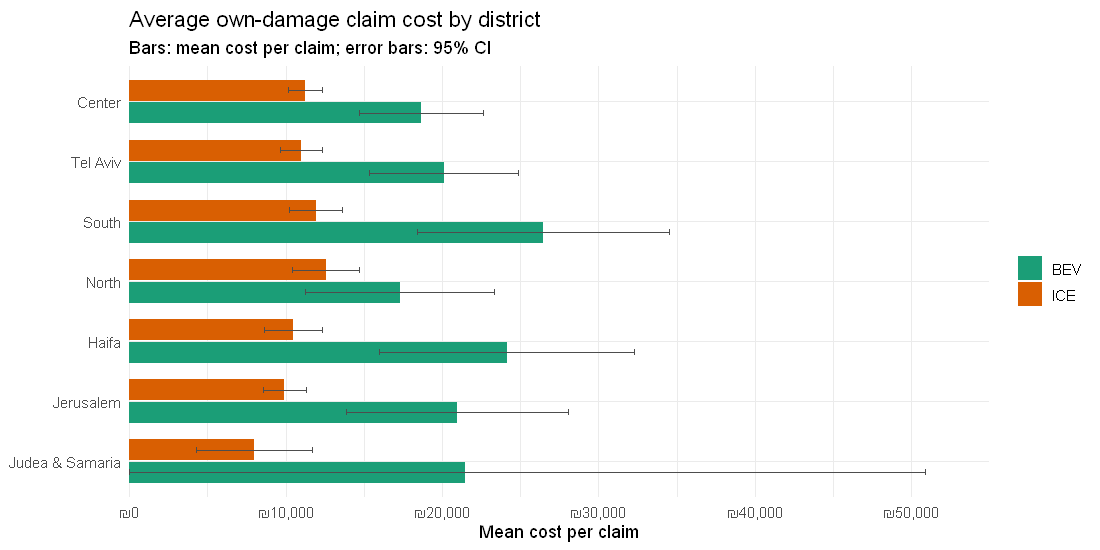

In [3]:
bar_chart(filter(sev_district), District, mean_cost, se, label_comma(prefix = "₪")) +
  coord_flip() +
  labs(title = "Average own-damage claim cost by district",
       subtitle = "Bars: mean cost per claim; error bars: 95% CI", y = "Mean cost per claim")

**Takeaway:** yes. In every district a BEV claim costs more than an ICE claim, from 1.4× in the North to 2.3× in Haifa. The BEV error bars are wide because each district has only 70–180 BEV claims, so the district-to-district differences are mostly noise. The BEV premium itself shows up everywhere.

Judea & Samaria shows high noise and wide dispersion for BEVs due to having only 4 observed claims.

## 3. Do BEVs claim more often in every district?
Own-damage claims per vehicle-year of exposure. As above, groups with fewer than 20 claims are not plotted.

In [4]:
freq_district <- freq_by(District, Powertrain) |>
  filter(District != "Unknown") |>
  mutate(District = factor(District, district_order))

freq_district |>
  select(District, Powertrain, frequency) |>
  pivot_wider(names_from = Powertrain, values_from = frequency) |>
  mutate(BEV_vs_ICE = number(BEV / ICE, 0.01), across(c(BEV, ICE), ~ percent(.x, 0.1))) |>
  arrange(desc(District))

District,BEV,ICE,BEV_vs_ICE
<fct>,<chr>,<chr>,<chr>
Center,16.3%,15.3%,1.06
Tel Aviv,19.5%,17.7%,1.11
South,16.9%,14.6%,1.16
North,14.5%,13.0%,1.12
Haifa,12.9%,13.7%,0.94
Jerusalem,14.5%,16.3%,0.89
Judea & Samaria,5.9%,10.9%,0.54


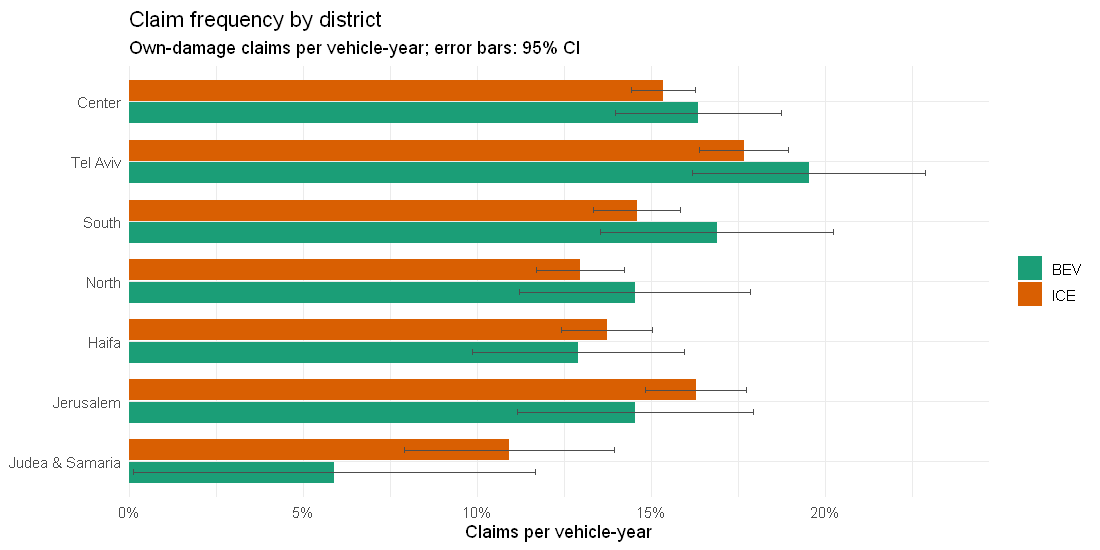

In [5]:
bar_chart(filter(freq_district), District, frequency, se, label_percent()) +
  coord_flip() +
  labs(title = "Claim frequency by district",
       subtitle = "Own-damage claims per vehicle-year; error bars: 95% CI", y = "Claims per vehicle-year")

**Takeaway:** frequency depends much more on *where* the car is than on what powers it. Tel Aviv is highest for both powertrains (about 18–20%), and the BEV/ICE ratio moves between 0.89 and 1.16 with no consistent direction. There is no district where BEVs clearly claim more often.

Judea & Samaria shows high noise and wide dispersion for BEVs due to having only 4 observed claims.

## 4. How do claim cost and write-offs change with vehicle value?

In [6]:
value_sev <- sev_by(value_tier, Powertrain) |> filter(!is.na(value_tier))
value_tl  <- tl_by(value_tier, Powertrain)  |> filter(!is.na(value_tier))

left_join(select(value_sev, value_tier, Powertrain, claims, mean_cost),
          select(value_tl, value_tier, Powertrain, tl_rate), by = c("value_tier", "Powertrain")) |>
  mutate(mean_cost = comma(mean_cost, 1, prefix = "₪"), tl_rate = percent(tl_rate, 0.1)) |>
  arrange(value_tier, Powertrain)

value_tier,Powertrain,claims,mean_cost,tl_rate
<fct>,<fct>,<int>,<chr>,<chr>
< ₪75k,BEV,93,"₪13,760",19.4%
< ₪75k,ICE,2510,"₪8,433",9.1%
₪75–150k,BEV,255,"₪19,900",9.4%
₪75–150k,ICE,1001,"₪16,160",6.2%
₪150k+,BEV,283,"₪24,226",4.3%
₪150k+,ICE,139,"₪23,782",3.8%


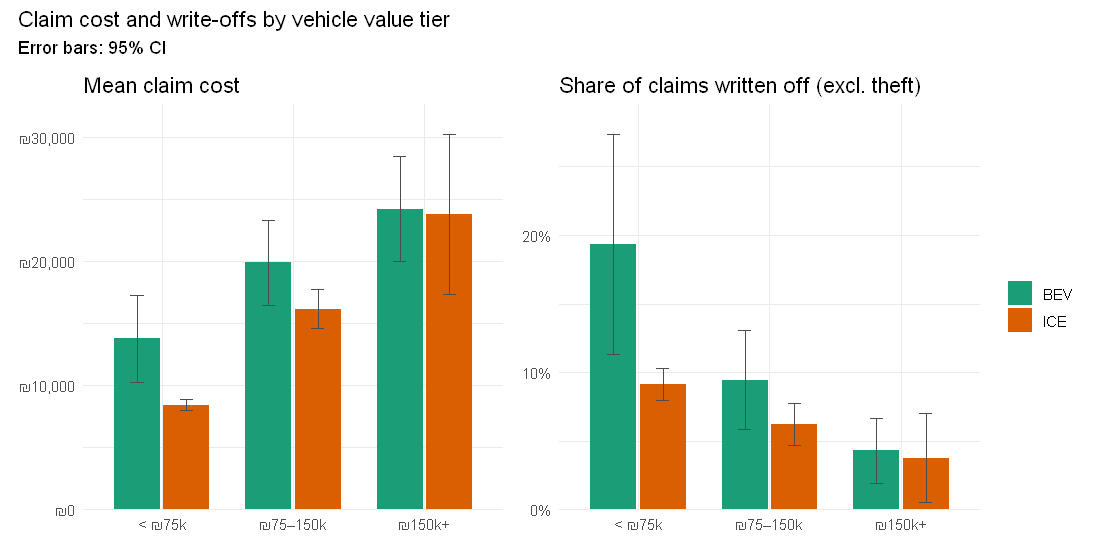

In [7]:
p_cost <- bar_chart(value_sev, value_tier, mean_cost, se, label_comma(prefix = "₪")) +
  labs(title = "Mean claim cost", y = NULL)
p_tl <- bar_chart(value_tl, value_tier, tl_rate, se, label_percent()) +
  labs(title = "Share of claims written off (excl. theft)", y = NULL)

(p_cost + p_tl) +
  plot_layout(guides = "collect") +
  plot_annotation(title = "Claim cost and write-offs by vehicle value tier",
                  subtitle = "Error bars: 95% CI")

**Takeaway:**
- **Claim cost:** rises with vehicle value for both powertrains. The BEV premium is largest for cheaper cars (₪13.8k vs. ₪8.4k under ₪75k) and almost disappears above ₪150k (₪24.2k vs. ₪23.8k).
- **Write-offs:** fall as value rises. BEVs are written off more often in every tier, most clearly under ₪75k (19.4% vs. 9.1%, though based on only 93 BEV claims).

## 5. How does claim frequency change with driver age?

In [8]:
driver_freq <- freq_by(driver_group, Powertrain) |> filter(!is.na(driver_group))

driver_freq |>
  select(driver_group, Powertrain, exposure, frequency) |>
  pivot_wider(names_from = Powertrain, values_from = c(exposure, frequency)) |>
  mutate(across(starts_with("exposure"), ~ comma(.x, 1)), across(starts_with("frequency"), ~ percent(.x, 0.1)))

driver_group,exposure_BEV,exposure_ICE,frequency_BEV,frequency_ICE
<fct>,<chr>,<chr>,<chr>,<chr>
Young (<25),427,"2,390",30.9%,33.6%
25–40,"1,011","6,150",13.0%,13.5%
41–60,"1,894","11,944",13.8%,13.1%
60+,594,"3,623",16.2%,12.7%


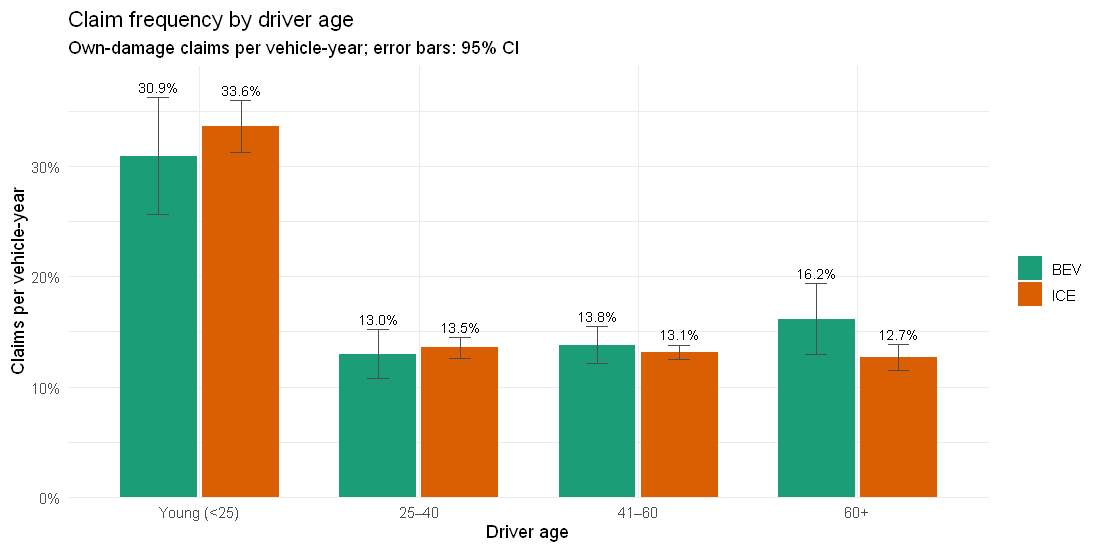

In [9]:
bar_chart(driver_freq, driver_group, frequency, se, label_percent()) +
  geom_text(aes(label = percent(frequency, 0.1), y = frequency + 1.96 * se),
            position = position_dodge(width = 0.75), vjust = -0.5, size = 3.3) +
  labs(title = "Claim frequency by driver age",
       subtitle = "Own-damage claims per vehicle-year; error bars: 95% CI",
       x = "Driver age", y = "Claims per vehicle-year")

**Takeaway:**
- **Young drivers:** drivers under 25 claim more than twice as often as everyone else (31–34% against about 13%), for BEV and ICE alike.
- **Ages 25 and up:** frequency is flat, and the two powertrains are close. The only gap, in the 60+ group (16.2% vs. 12.7%), sits inside overlapping error bars.

Driver age matters a lot for frequency, but it does not explain the BEV/ICE difference.

## 6. How do repair cost and write-offs change as cars get older?
Groups with fewer than 20 claims are not plotted: there are very few BEVs older than 9 years.

In [10]:
age_tl <- tl_by(car_age, Powertrain)

sev_by(car_age, Powertrain) |>
  select(car_age, Powertrain, claims, median_cost, mean_cost) |>
  left_join(select(age_tl, car_age, Powertrain, tl_rate), by = c("car_age", "Powertrain")) |>
  mutate(across(c(median_cost, mean_cost), ~ comma(.x, 1, prefix = "₪")), tl_rate = percent(tl_rate, 0.1)) |>
  arrange(car_age, Powertrain)

car_age,Powertrain,claims,median_cost,mean_cost,tl_rate
<fct>,<fct>,<int>,<chr>,<chr>,<chr>
0–2 yrs,BEV,421,"₪10,436","₪22,047",5.8%
0–2 yrs,ICE,441,"₪6,597","₪16,853",4.9%
3–5 yrs,BEV,141,"₪8,502","₪22,977",13.6%
3–5 yrs,ICE,1025,"₪6,081","₪13,892",6.0%
6–9 yrs,BEV,53,"₪4,238","₪10,287",13.2%
6–9 yrs,ICE,1107,"₪4,571","₪10,800",8.2%
10+ yrs,BEV,16,"₪6,092","₪8,957",25.0%
10+ yrs,ICE,1077,"₪3,378","₪6,520",11.6%


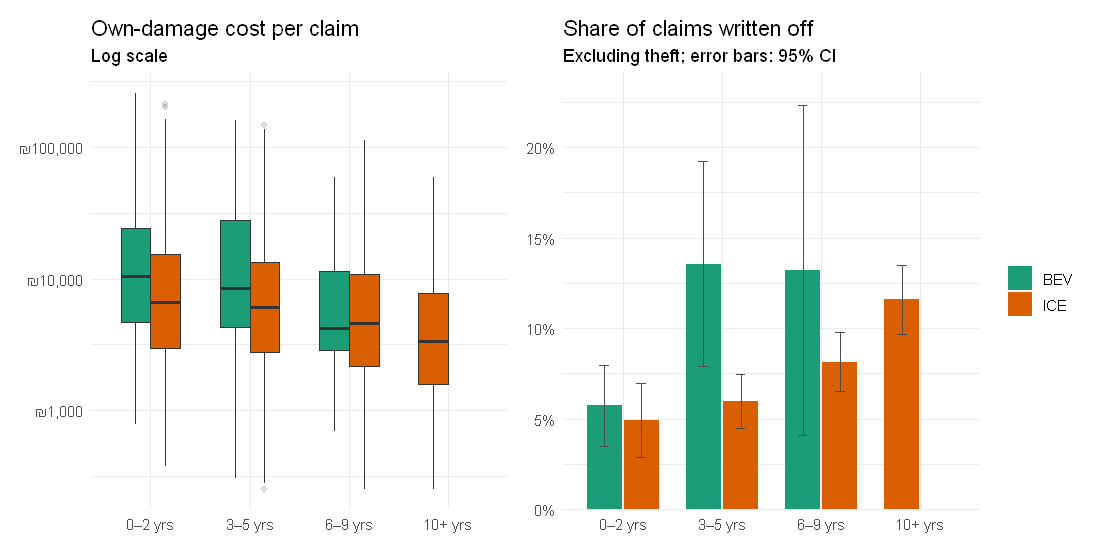

In [11]:
enough <- sev_data |> count(car_age, Powertrain) |> filter(n >= 20)

p_box <- sev_data |>
  semi_join(enough, by = c("car_age", "Powertrain")) |>
  ggplot(aes(car_age, Own_Damage_Amount, fill = Powertrain)) +
  geom_boxplot(outlier.alpha = 0.15, width = 0.6, position = position_dodge(preserve = "single")) +
  scale_fill_manual(values = pt_colours) +
  scale_y_log10(labels = label_comma(prefix = "₪")) +
  labs(title = "Own-damage cost per claim", subtitle = "Log scale", x = NULL, y = NULL) +
  guides(fill = "none")                                                # legend shown once, on the right panel

p_wo <- bar_chart(filter(age_tl, claims >= 20), car_age, tl_rate, se, label_percent()) +
  labs(title = "Share of claims written off", subtitle = "Excluding theft; error bars: 95% CI", y = NULL)

(p_box + p_wo) + plot_layout(guides = "collect")

**Takeaway:**
- **Repair cost:** falls as cars get older (ICE median ₪6.6k at 0–2 years vs. ₪3.4k at 10+). The BEV cost premium is concentrated in cars up to 5 years old, which is where almost all BEVs are.
- **Write-offs:** rise with age, because a repair costs more relative to an old car's value. BEVs are written off more often than ICE cars of the same age in every band they appear in.

## 7. Loss Ratio: Do Premiums Cover the Claims?
The **loss ratio** puts the premium next to the claims: incurred claims ÷ earned premium. It combines frequency and severity into one number and shows whether the current tariff charges each powertrain enough for its risk:
$$\text{Loss Ratio} = \frac{\text{Incurred claims}}{\text{Earned premium}} = \frac{\text{Frequency} \times \text{Severity}}{\text{Premium per vehicle-year}}$$

**Definitions:**
- **Earned premium:** `Premium` is the premium for the policy period, pro rata to exposure (partial-year policies pay the same per vehicle-year), so its sum is the earned premium. The 40 policies with no premium are left out.
- **Incurred claims:** own damage + third-party damage of every claim inside the policy period, including third-party-only claims and theft. The 12 own-damage amounts above 2 × vehicle value (entry errors) are excluded.
- **Own damage vs. third party:** the data has a single premium with no split, so we show what share of the premium each part of the claims uses up.
- **Storm and Hybrid:** the 2025-01-19 storm is excluded in the main figures and compared separately. All three powertrains are shown here, including Hybrid.

In [12]:
# Own data for this section: all three powertrains (the objects above are BEV vs. ICE only)
lr_policies <- read_rds(processed_path("policies_cleaned.rds")) |>
  filter(!is.na(Premium)) |>
  mutate(Powertrain = factor(as.character(Powertrain), levels = c("ICE", "Hybrid", "BEV")),
         value_tier = cut(Vehicle_Value, c(0, 75e3, 150e3, Inf), right = FALSE,
                          labels = c("< ₪75k", "₪75–150k", "₪150k+")),
         car_age    = cut(Vehicle_Age, c(-Inf, 2, 5, 9, Inf),
                          labels = c("0–2 yrs", "3–5 yrs", "6–9 yrs", "10+ yrs")))

# All claims inside the policy period, without the > 2x vehicle value entry errors
lr_claims <- read_rds(processed_path("claims_cleaned.rds")) |>
  inner_join(select(lr_policies, Policy_ID, Start_Date, End_Date, Powertrain, Vehicle_Value, value_tier, car_age),
             by = "Policy_ID", relationship = "many-to-one") |>
  filter(between(Accident_Date, Start_Date, End_Date),
         is.na(Vehicle_Value) | Own_Damage_Amount <= 2 * Vehicle_Value)

# Premium, claims and loss ratio by group; with_cat = TRUE keeps the storm claims
loss_ratio <- function(..., with_cat = FALSE) {
  cl   <- if (with_cat) lr_claims else filter(lr_claims, !is_cat_event)
  prem <- lr_policies |> group_by(...) |>
    summarise(premium = sum(Premium), exposure = sum(exposure), .groups = "drop")
  inc  <- cl |> group_by(...) |>
    summarise(claims = n(), od = sum(Own_Damage_Amount), tp = sum(TP_Damage_Amount), .groups = "drop")
  keys <- setdiff(names(prem), c("premium", "exposure"))
  prem |>
    left_join(inc, by = keys) |>
    mutate(across(c(claims, od, tp), ~ coalesce(.x, 0)),
           incurred = od + tp,
           loss_ratio = incurred / premium, lr_od = od / premium, lr_tp = tp / premium)
}

lr_pt <- loss_ratio(Powertrain)

lr_pt |>
  transmute(Powertrain,
            earned_premium   = comma(premium, 1, prefix = "₪"),
            incurred_claims  = comma(incurred, 1, prefix = "₪"),
            loss_ratio       = percent(loss_ratio, 0.1),
            of_which_od      = percent(lr_od, 0.1),
            of_which_tp      = percent(lr_tp, 0.1),
            exposure_vy      = comma(exposure, 1),
            premium_per_vy   = comma(premium / exposure, 1, prefix = "₪"))

Powertrain,earned_premium,incurred_claims,loss_ratio,of_which_od,of_which_tp,exposure_vy,premium_per_vy
<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ICE,"₪97,595,901","₪59,988,990",61.5%,41.9%,19.6%,"24,487","₪3,986"
Hybrid,"₪39,416,566","₪27,876,954",70.7%,57.1%,13.7%,"7,829","₪5,035"
BEV,"₪21,423,862","₪16,270,887",75.9%,61.7%,14.3%,"3,977","₪5,386"


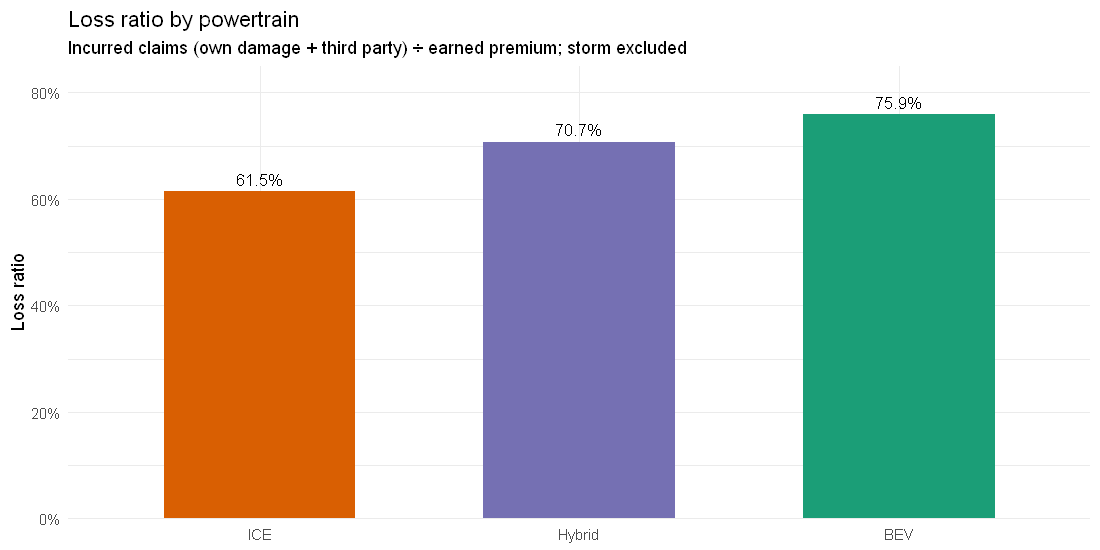

In [13]:
ggplot(lr_pt, aes(Powertrain, loss_ratio, fill = Powertrain)) +
  geom_col(width = 0.6) +
  geom_text(aes(label = percent(loss_ratio, 0.1)), vjust = -0.5, size = 4) +
  scale_fill_manual(values = pt_colours, guide = "none") +
  scale_y_continuous(labels = percent, expand = expansion(mult = c(0, 0.12))) +
  labs(title = "Loss ratio by powertrain",
       subtitle = "Incurred claims (own damage + third party) ÷ earned premium; storm excluded",
       x = NULL, y = "Loss ratio")

### 7.1 With and without the storm

In [14]:
left_join(select(lr_pt, Powertrain, without_storm = loss_ratio),
          select(loss_ratio(Powertrain, with_cat = TRUE), Powertrain, with_storm = loss_ratio),
          by = "Powertrain") |>
  mutate(storm_adds = percent(with_storm - without_storm, 0.1, suffix = " pp"),
         across(c(without_storm, with_storm), ~ percent(.x, 0.1)))

Powertrain,without_storm,with_storm,storm_adds
<fct>,<chr>,<chr>,<chr>
ICE,61.5%,63.1%,1.7 pp
Hybrid,70.7%,72.7%,2.0 pp
BEV,75.9%,78.7%,2.8 pp


### 7.2 Frequency × severity vs. premium
The loss ratio splits into the risk side (frequency × severity = claims cost per vehicle-year) and the price side (premium per vehicle-year). The last row compares each powertrain with ICE.

In [15]:
decomp <- lr_pt |>
  transmute(Powertrain,
            frequency      = claims / exposure,
            cost_per_claim = incurred / claims,
            claims_per_vy  = incurred / exposure,          # = frequency x cost per claim
            premium_per_vy = premium / exposure,
            loss_ratio)

bind_rows(
  decomp |> mutate(frequency = percent(frequency, 0.1),
                   across(c(cost_per_claim, claims_per_vy, premium_per_vy), ~ comma(.x, 1, prefix = "₪")),
                   loss_ratio = percent(loss_ratio, 0.1)),
  decomp |> filter(Powertrain == "BEV") |>
    transmute(Powertrain = "BEV ÷ ICE",
              across(frequency:loss_ratio, ~ number(.x / decomp[[cur_column()]][decomp$Powertrain == "ICE"], 0.01)))
)

Powertrain,frequency,cost_per_claim,claims_per_vy,premium_per_vy,loss_ratio
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ICE,16.0%,"₪15,288","₪2,450","₪3,986",61.5%
Hybrid,16.6%,"₪21,411","₪3,561","₪5,035",70.7%
BEV,16.9%,"₪24,213","₪4,091","₪5,386",75.9%
BEV ÷ ICE,1.05,1.58,1.67,1.35,1.24


### 7.3 Is it value or age?
BEVs are newer and more expensive than ICE cars. If the loss ratio were only a value or age effect, BEVs would match ICE *within* each value tier and age group. Groups with fewer than 20 claims are not plotted.

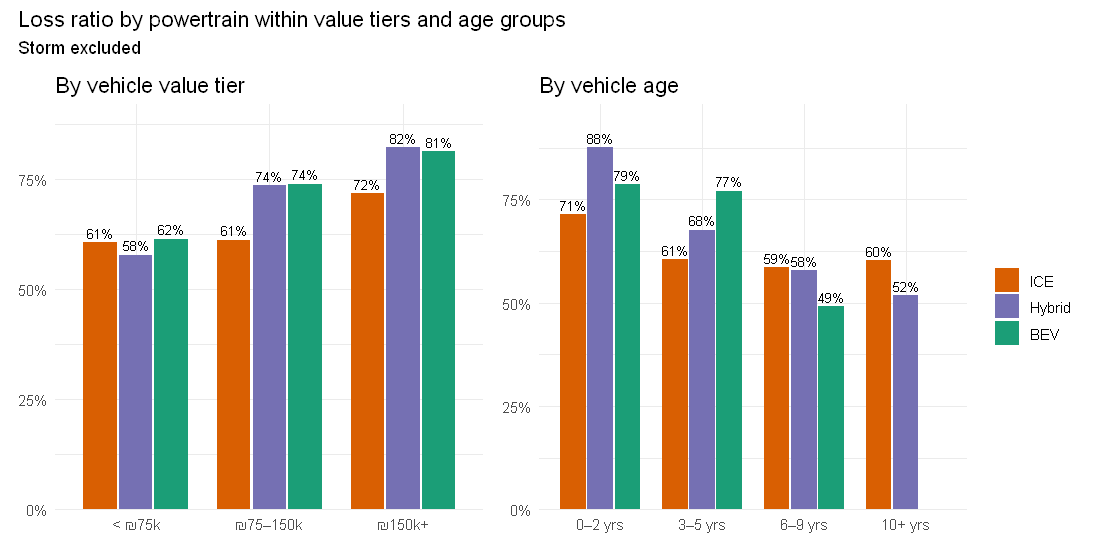

In [16]:
lr_bar <- function(data, x) {
  ggplot(filter(data, claims >= 20), aes({{ x }}, loss_ratio, fill = Powertrain)) +
    geom_col(position = position_dodge(width = 0.8, preserve = "single"), width = 0.75) +
    geom_text(aes(label = percent(loss_ratio, 1)), position = position_dodge(width = 0.8, preserve = "single"),
              vjust = -0.4, size = 3) +
    scale_fill_manual(values = pt_colours) +
    scale_y_continuous(labels = percent, expand = expansion(mult = c(0, 0.12))) +
    labs(x = NULL, y = NULL, fill = NULL)
}

lr_value <- loss_ratio(value_tier, Powertrain) |> filter(!is.na(value_tier))
lr_age   <- loss_ratio(car_age, Powertrain)

(lr_bar(lr_value, value_tier) + labs(title = "By vehicle value tier") +
   lr_bar(lr_age, car_age) + labs(title = "By vehicle age")) +
  plot_layout(guides = "collect") +
  plot_annotation(title = "Loss ratio by powertrain within value tiers and age groups",
                  subtitle = "Storm excluded")

**Takeaway:**
- **Overall:** the current tariff earns less on BEVs than on ICE. The loss ratio is 75.9% for BEV, 70.7% for Hybrid and 61.5% for ICE, storm excluded.
- **Why:** a BEV costs 1.67× as much in claims per vehicle-year as an ICE car (frequency 1.05× × cost per claim 1.58×), but its premium is only 1.35× higher. The loss ratio gap (1.24×) is the part of the extra risk that the price does not cover.
- **Own damage vs. third party:** the gap comes from own damage (61.7% vs. 41.9% of premium). Third-party claims use up a *smaller* share of the BEV premium (14.3% vs. 19.6%), in line with the third-party test in notebook 03.
- **Value or age?** Not only. Within the ₪75–150k and ₪150k+ tiers and for cars up to 5 years old, BEVs still have a 9–16 point higher loss ratio than ICE. Only in the cheapest tier are they level (62% vs. 61%).
- **Value pattern for all powertrains:** the loss ratio rises with value, so expensive cars in general are underpriced relative to cheap ones.
- **Storm:** adds 1.7–2.8 points and does not change the ranking.

This matches the GLM result in notebook 04: at equal rating factors, BEVs need about a 1.29× pure premium. The current tariff loads BEVs, but not enough.

## 8. Key Findings

- **Repair cost:** BEVs cost more to repair in every district (1.4–2.3×). The gap is largest for cheaper and newer cars and almost gone above ₪150k, so vehicle value explains a large part of it.
- **Claim frequency:** depends on district and, above all, driver age (under-25s claim at about 2.5× the rate of older drivers), much more than on powertrain.
- **Write-offs:** BEVs are written off more often than ICE cars of the same value tier and the same age band. This is consistent with the battery-damage argument and with the total-loss GLM in notebook 04.
- **Loss ratio:** the current premium covers BEV claims less well than ICE claims (75.9% vs. 61.5%, storm excluded). BEV claims cost 1.67× ICE per vehicle-year, but the premium is only 1.35× higher, and the gap remains within value tiers and newer age groups.
- **What these charts imply for pricing:** vehicle value, vehicle age, district and driver age all need to be in the model before the BEV effect is measured. That is how notebook 04 is built.